# Supplier cybersecurity incidents — verbose



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_score, recall_score,
                             RocCurveDisplay, confusion_matrix, auc, roc_curve)
from sklearn.model_selection import train_test_split





In [2]:
random_variable = 20261026

### Helper Functions

In [3]:
def evaluate_model(y_true, y_pred, print_results=True):
    cnf_matrix = confusion_matrix(y_true, y_pred, labels=[True, False])
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matrix.T, 
                                 display_labels=['cybersecurity incident', 'no cybersecurity incident'])

    # Create a figure and plot
    if print_results:
        fig, ax = plt.subplots(figsize=(8, 6))
        disp.plot(ax=ax, cmap='Blues')
        plt.xlabel('Actual Condition')  # This will now be on the x-axis
        plt.ylabel('Predicted Condition')  # This will now be on the y-axis
        plt.title('Confusion Matrix for Cybersecurity Incidents')    
        plt.show()

    # Add precision, recall, and F1-score
    accuracy = round(accuracy_score(y_true, y_pred), 4)
    precision = round(precision_score(y_true, y_pred), 4)
    recall = round(recall_score(y_true, y_pred), 4)
    f1 = round(f1_score(y_true, y_pred), 4)
    if print_results:
        print(f'Accuracy: {accuracy:.2f}')
        print(f'Precision: {precision:.2f}')
        print(f'Recall: {recall:.2f}')
        print(f'F1-score: {f1:.2f}')

    return accuracy, precision, recall, f1


## 1. Load and merge the data

In [ ]:
folder_path = "https://raw.github.com/jan-source/ppa_erp_student/main/case_1_supplier/"

In [ ]:
master = pd.read_excel(folder_path + 'supplier_master.xlsx')
assessment = pd.read_excel(folder_path + 'cybersecurity_assessment.xlsx')

In [6]:
data = master.merge(assessment, on='supplier_id', how='inner')

In [7]:
data.head()

,supplier_id,supplier_name,industry,country,employees,annual_revenue_m_eur,years_as_supplier,business_criticality,access_level,sensitive_data_access,...,average_patch_delay_days,mfa_coverage_pct,security_training_coverage_pct,prior_incidents_3y,fourth_party_dependency_count,iso27001_certified,incident_response_plan_tested,cyber_insurance,security_questionnaire_score,cybersecurity_incident_past_12m
0,SUP-0001,Prime Digital 0001,Professional services,Germany,417,48.9,4,High,Portal only,True,...,93.0,58.0,69.0,0,5,False,False,False,45.0,True
1,SUP-0002,Evergreen Works 0002,Logistics,Poland,20,3.6,9,Medium,No access,False,...,80.0,41.0,61.0,0,2,False,False,False,51.0,False
2,SUP-0003,Blue Networks 0003,Industrial manufacturing,Mexico,276,43.2,8,Medium,Portal only,False,...,72.0,57.0,17.0,1,0,False,False,False,58.0,False
3,SUP-0004,Central Industries 0004,Electronics,Poland,103,22.0,2,Low,Portal only,False,...,50.0,76.0,75.0,0,1,False,False,True,86.0,False
4,SUP-0005,Global Supply 0005,IT services,Germany,809,68.4,5,Medium,Business systems,True,...,36.0,86.0,55.0,1,7,False,False,True,82.0,False


**Share of Suppliers with Cybersecurity Incidence**

In [8]:
print(str(data['cybersecurity_incident_past_12m'].mean().round(3) * 100) + "%")

20.3%


## 2. Remove incomplete observations

Identifiers are excluded before checking model predictors. Rows with at least one missing predictor are then removed. This is simple, but it reduces the sample and may introduce bias if values are not missing completely at random.

**%-of Missing observations by column**

In [9]:
(data.isna().sum() / data.shape[0]).round(3) * 100

supplier_id                        0.0
supplier_name                      0.0
industry                           0.0
country                            0.0
employees                          0.0
annual_revenue_m_eur               0.0
years_as_supplier                  0.0
business_criticality               0.0
access_level                       0.0
sensitive_data_access              0.0
external_attack_surface_score      0.0
security_rating                    2.5
average_patch_delay_days           3.4
mfa_coverage_pct                   3.8
security_training_coverage_pct     2.6
prior_incidents_3y                 0.0
fourth_party_dependency_count      0.0
iso27001_certified                 0.0
incident_response_plan_tested      0.0
cyber_insurance                    0.0
security_questionnaire_score       3.5
cybersecurity_incident_past_12m    0.0
dtype: float64

In [10]:
complete_data = data.dropna().copy()


###

## 3. Preprocessing



Get Categorical Columns

In [11]:
complete_data.dtypes

supplier_id                            str
supplier_name                          str
industry                               str
country                                str
employees                            int64
annual_revenue_m_eur               float64
years_as_supplier                    int64
business_criticality                   str
access_level                           str
sensitive_data_access                 bool
external_attack_surface_score        int64
security_rating                    float64
average_patch_delay_days           float64
mfa_coverage_pct                   float64
security_training_coverage_pct     float64
prior_incidents_3y                   int64
fourth_party_dependency_count        int64
iso27001_certified                    bool
incident_response_plan_tested         bool
cyber_insurance                       bool
security_questionnaire_score       float64
cybersecurity_incident_past_12m       bool
dtype: object

In [12]:
complete_data.columns

Index(['supplier_id', 'supplier_name', 'industry', 'country', 'employees',
       'annual_revenue_m_eur', 'years_as_supplier', 'business_criticality',
       'access_level', 'sensitive_data_access',
       'external_attack_surface_score', 'security_rating',
       'average_patch_delay_days', 'mfa_coverage_pct',
       'security_training_coverage_pct', 'prior_incidents_3y',
       'fourth_party_dependency_count', 'iso27001_certified',
       'incident_response_plan_tested', 'cyber_insurance',
       'security_questionnaire_score', 'cybersecurity_incident_past_12m'],
      dtype='str')

**Get overview about target variables**

In [13]:
complete_data['cybersecurity_incident_past_12m'].mean()

np.float64(0.20703125)

**Get an overview by industry, country, business criticality and access level**

In [14]:
complete_data.groupby('industry')['cybersecurity_incident_past_12m'].mean()

industry
Cloud and software          0.192308
Electronics                 0.186441
IT services                 0.260684
Industrial manufacturing    0.202454
Logistics                   0.190789
Professional services       0.183099
Name: cybersecurity_incident_past_12m, dtype: float64

IT Services seems to have a higher mean of cybersecurity incidents in the past 12 months compared to other industries.

In [15]:
complete_data.groupby('country')['cybersecurity_incident_past_12m'].mean().round(3)

country
Austria        0.213
France         0.220
Germany        0.233
India          0.140
Mexico         0.182
Netherlands    0.205
Poland         0.198
USA            0.218
Name: cybersecurity_incident_past_12m, dtype: float64

India seems to have a lower risk than other countries

In [16]:
complete_data.groupby('business_criticality')['cybersecurity_incident_past_12m'].mean().round(3)

business_criticality
Critical    0.259
High        0.177
Low         0.240
Medium      0.195
Name: cybersecurity_incident_past_12m, dtype: float64

The risk seems higher for business-critical operations compared to less critical ones.

In [17]:
complete_data.groupby('access_level')['cybersecurity_incident_past_12m'].mean().round(3)

access_level
Business systems    0.229
No access           0.176
Portal only         0.171
Privileged          0.314
Name: cybersecurity_incident_past_12m, dtype: float64

<mark>Privileged</mark> seem to have a higher risk of cybersecurity instances

Define Categorical Variables

In [18]:
categorical_columns = ["industry", "country", "business_criticality", "access_level"]


Construct Feature List

In [19]:
features_numeric = [col for col in complete_data.columns 
    if col != 'cybersecurity_incident_past_12m' and complete_data[col].dtype != 'str']

In [20]:
features_numeric

['employees',
 'annual_revenue_m_eur',
 'years_as_supplier',
 'sensitive_data_access',
 'external_attack_surface_score',
 'security_rating',
 'average_patch_delay_days',
 'mfa_coverage_pct',
 'security_training_coverage_pct',
 'prior_incidents_3y',
 'fourth_party_dependency_count',
 'iso27001_certified',
 'incident_response_plan_tested',
 'cyber_insurance',
 'security_questionnaire_score']

### Add categorical Variables construct two list one with supplier dummies and one without

In [21]:
features_with_dummies = features_numeric.copy()

**Dummy‑variable trap** 
- All category columns sum to 1 → perfect multicollinearity 
- drop_first=True avoids this.
- only issue with logistic regression


In [22]:

for c in categorical_columns:
    print(f"Processing column: {c}")
    dummies = pd.get_dummies(complete_data[c], prefix=c, drop_first=True)        
    features_with_dummies = features_with_dummies + list(dummies.columns)        
    complete_data = pd.concat([complete_data, dummies], axis=1)


Processing column: industry
Processing column: country
Processing column: business_criticality
Processing column: access_level


**Total Number of Features including Dummies for Categorical Variables

In [23]:
len(features_with_dummies)

33

## 4. Fit Models

### Logistic Regression

In [24]:
log_reg_simple = LogisticRegression(random_state=random_variable)

In [25]:
log_reg_simple.fit(complete_data[features_numeric], complete_data['cybersecurity_incident_past_12m'])

/Users/jan/Documents/02_teaching/ohm/01_PPA_ERP/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",20261026
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the follo

Get Overview of coefficients

In [26]:
pd.DataFrame({'feature': features_numeric, 'coefficients': log_reg_simple.coef_[0]})

,feature,coefficients
0,employees,0.000186
1,annual_revenue_m_eur,-0.001957
2,years_as_supplier,0.045855
3,sensitive_data_access,0.230967
4,external_attack_surface_score,0.009666
5,security_rating,-0.035390
6,average_patch_delay_days,0.014428
7,mfa_coverage_pct,-0.007337
8,security_training_coverage_pct,-0.004568
9,prior_incidents_3y,0.387232


Create predictions and calculate performance metrics

In [27]:
predictions_log_only_numeric = log_reg_simple.predict(complete_data[features_numeric])


In [28]:
confusion_matrix(complete_data['cybersecurity_incident_past_12m'], predictions_log_only_numeric, labels=[True, False]).T

array([[ 50,  33],
       [162, 779]])

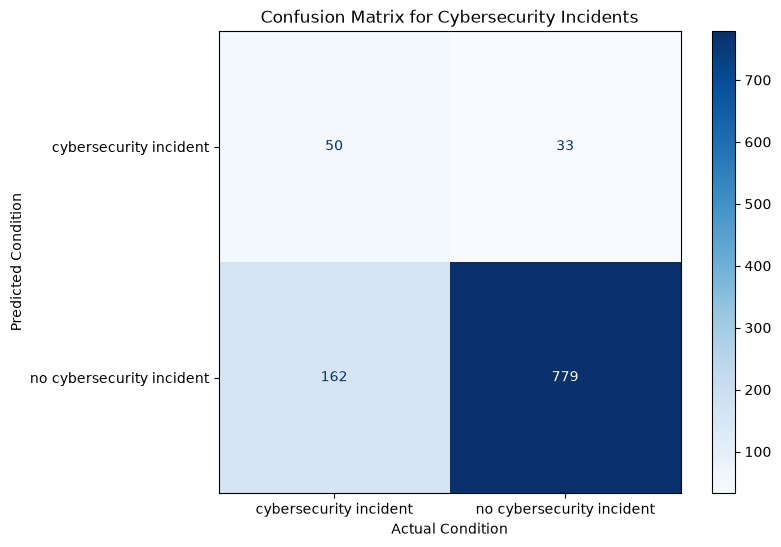

Accuracy: 0.81
Precision: 0.60
Recall: 0.24
F1-score: 0.34


In [29]:
accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_log_only_numeric)

In [30]:
log_reg_simple_w_dummies = LogisticRegression(random_state=random_variable)
log_reg_simple_w_dummies.fit(complete_data[features_with_dummies], complete_data['cybersecurity_incident_past_12m'])
predictions_log_w_dummies = log_reg_simple_w_dummies.predict(complete_data[features_with_dummies])

/Users/jan/Documents/02_teaching/ohm/01_PPA_ERP/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [31]:
pd.DataFrame({'feature': features_with_dummies, 'coefficients': log_reg_simple_w_dummies.coef_[0]})

,feature,coefficients
0,employees,0.000142
1,annual_revenue_m_eur,-0.001678
2,years_as_supplier,0.111544
3,sensitive_data_access,0.081112
4,external_attack_surface_score,0.011821
5,security_rating,-0.033673
6,average_patch_delay_days,0.016269
7,mfa_coverage_pct,-0.006514
8,security_training_coverage_pct,-0.003406
9,prior_incidents_3y,0.150838


**Summary**
Coefficients partly reflect what we have seen from the descriptive analysis, e.g.:
- Coefficient for country_India has a negative sign (indicating lower risk)
- Coefficient for industry_IT services is positive (indicating higher risk)

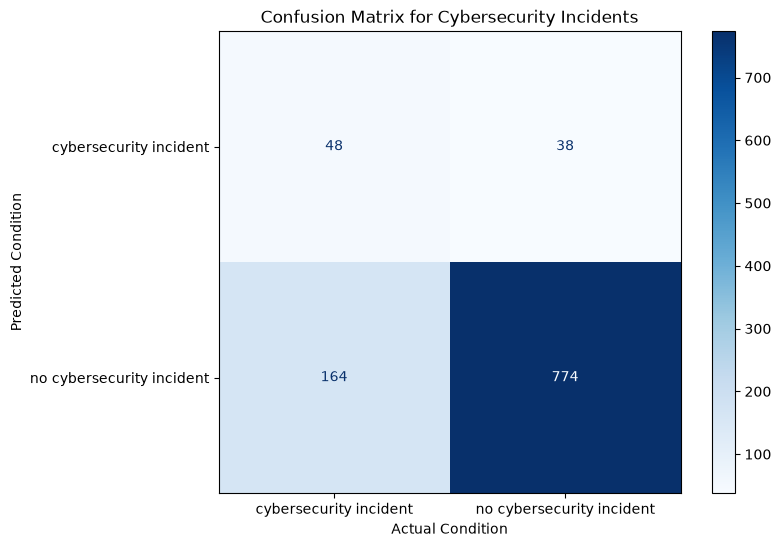

Accuracy: 0.80
Precision: 0.56
Recall: 0.23
F1-score: 0.32


In [32]:
accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_log_w_dummies )

### Decision Tree

Tree with 3-Level of Depth

In [33]:
decision_tree_numeric_features = DecisionTreeClassifier(random_state=random_variable, max_depth=3)
decision_tree_numeric_features.fit(complete_data[features_numeric], complete_data['cybersecurity_incident_past_12m'])
predictions_tree_numeric_features = decision_tree_numeric_features.predict(complete_data[features_numeric])

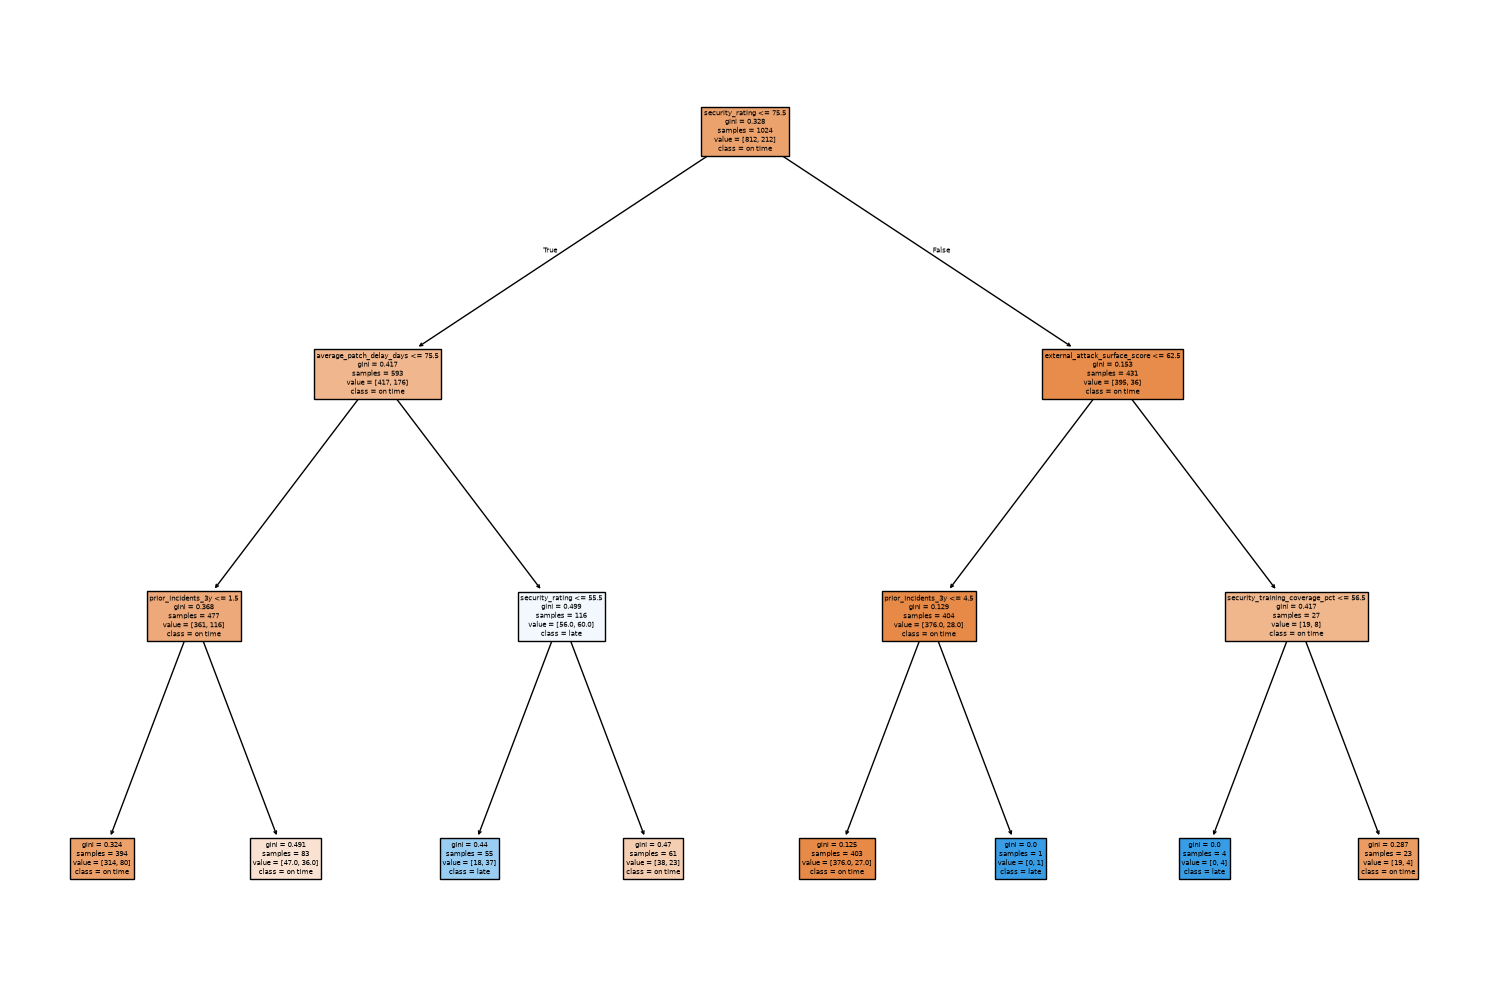

In [34]:
plt.figure(figsize=(15, 10))
tree.plot_tree(
        decision_tree_numeric_features, 
        feature_names=features_numeric, 
        class_names=['on time', 'late'], 
        filled=True
        )
plt.tight_layout()
plt.savefig('decision_tree_visualization_wo_supplier.png', dpi=300, bbox_inches='tight')
plt.show()

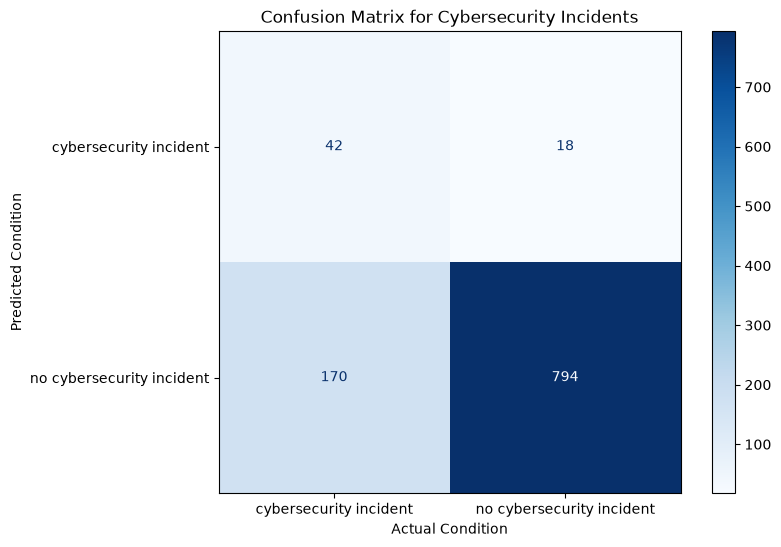

Accuracy: 0.82
Precision: 0.70
Recall: 0.20
F1-score: 0.31


In [35]:
accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_tree_numeric_features)

**Increasing level of depth to 5**

In [36]:
decision_tree_numeric_features = DecisionTreeClassifier(random_state=random_variable, max_depth=5)
decision_tree_numeric_features.fit(complete_data[features_numeric], complete_data['cybersecurity_incident_past_12m'])
predictions_tree_numeric_features = decision_tree_numeric_features.predict(complete_data[features_numeric])

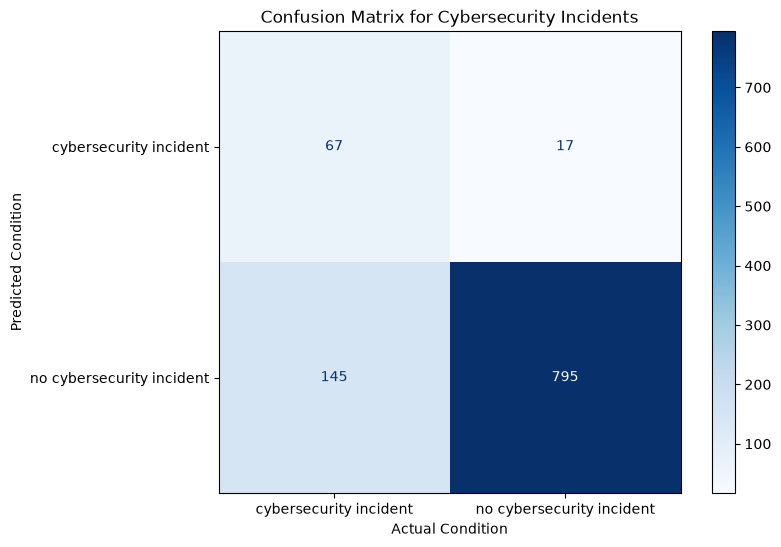

Accuracy: 0.84
Precision: 0.80
Recall: 0.32
F1-score: 0.45


In [37]:
accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_tree_numeric_features)

**Decision Tree with Supplier Feature and 3-Level of depth**

In [38]:
decision_tree_w_dummies = DecisionTreeClassifier(random_state=random_variable, max_depth=3)
decision_tree_w_dummies.fit(complete_data[features_with_dummies], complete_data['cybersecurity_incident_past_12m'])
predictions_tree_w_dummies = decision_tree_w_dummies.predict(complete_data[features_with_dummies])

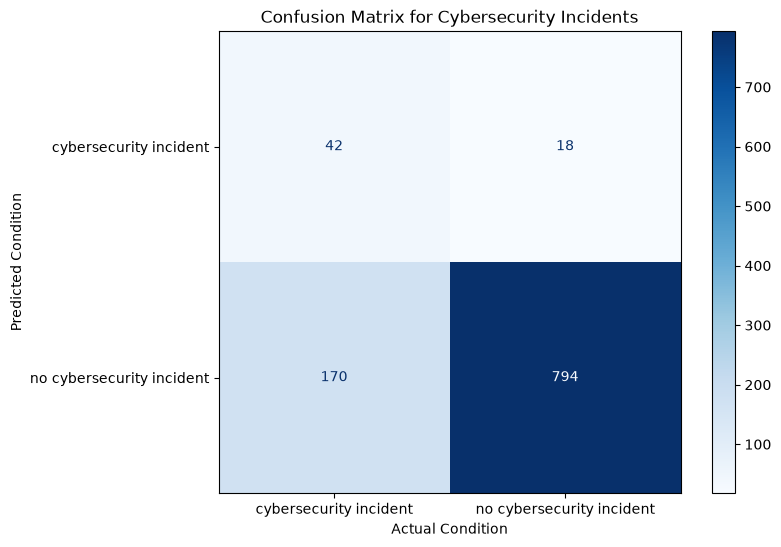

Accuracy: 0.82
Precision: 0.70
Recall: 0.20
F1-score: 0.31


In [39]:
accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_tree_w_dummies)

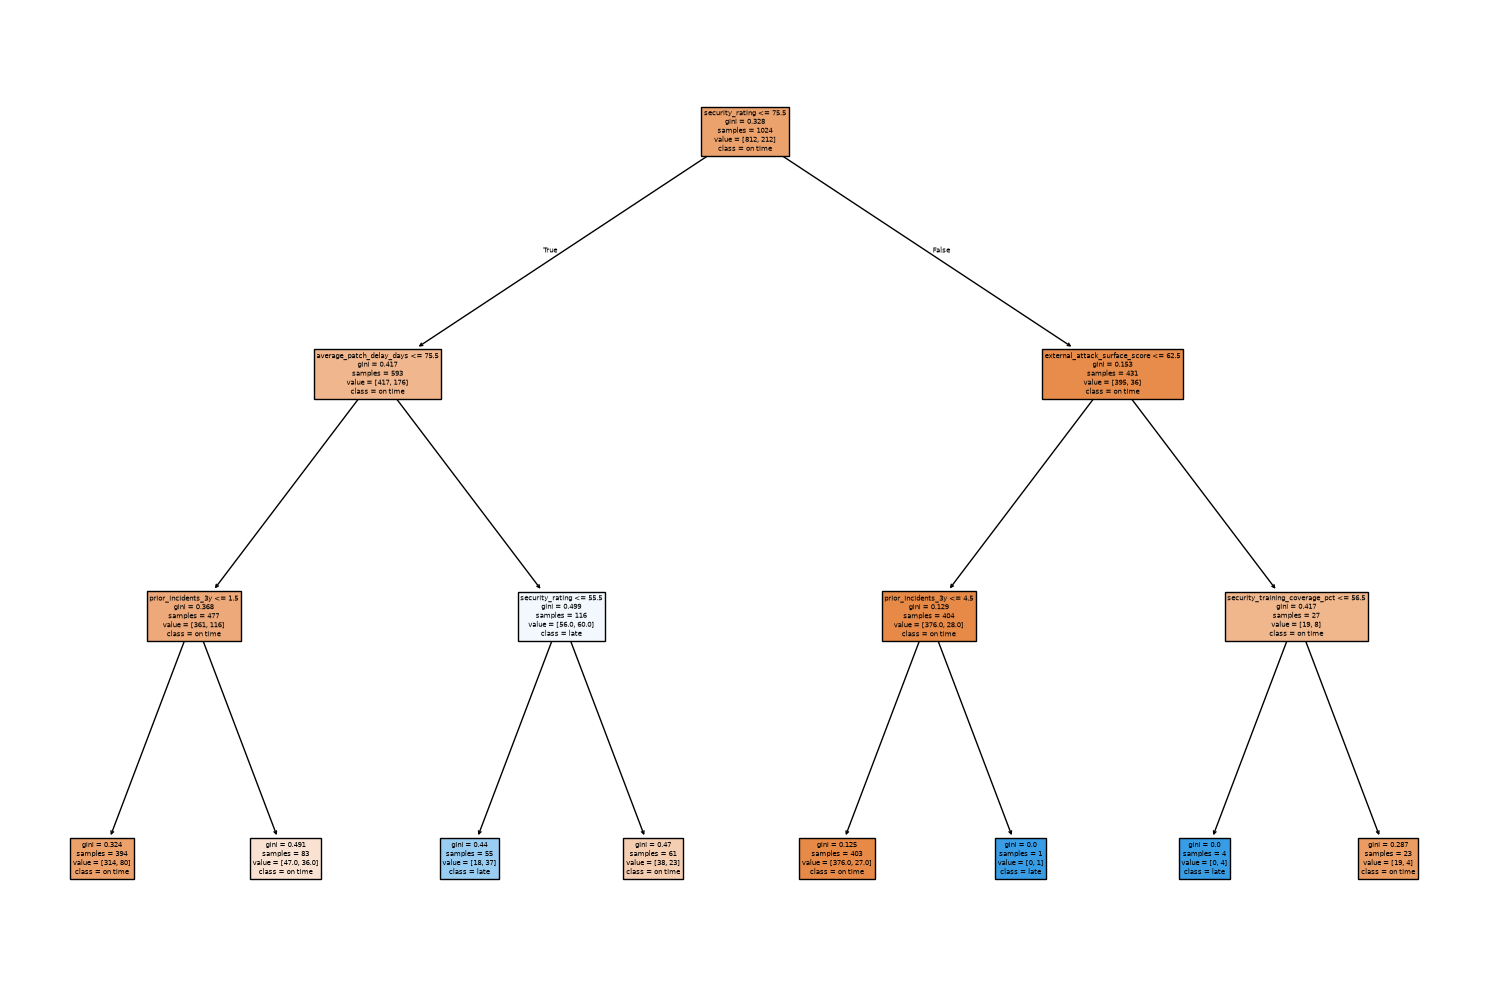

In [40]:
plt.figure(figsize=(15, 10))
tree.plot_tree(
        decision_tree_w_dummies, 
        feature_names=features_with_dummies, 
        class_names=['on time', 'late'], 
        filled=True
        )
plt.tight_layout()
plt.savefig('decision_tree_visualization_w_supplier.png', dpi=300, bbox_inches='tight')
plt.show()

**Increasing to 5 Levels of Depth**

In [41]:
decision_tree_w_dummies = DecisionTreeClassifier(random_state=random_variable, max_depth=5)
decision_tree_w_dummies.fit(complete_data[features_with_dummies], complete_data['cybersecurity_incident_past_12m'])
predictions_tree_w_dummies = decision_tree_w_dummies.predict(complete_data[features_with_dummies])

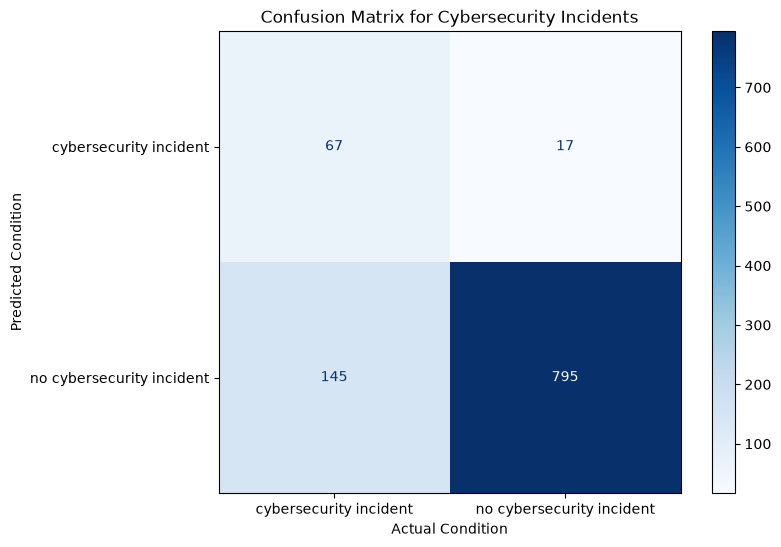

Accuracy: 0.84
Precision: 0.80
Recall: 0.32
F1-score: 0.45


In [42]:
accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_tree_w_dummies)

#### Summary
Unlike the Logistic Regressions the decision tree stays robust even if adding the large number of variables for supplier to the model


### Compare Different tree depth

In [43]:
results_tree = []
for i in range(2,15):
    decision_tree_w_supplier_ = DecisionTreeClassifier(random_state=random_variable, max_depth=i)
    decision_tree_w_supplier_.fit(complete_data[features_with_dummies], complete_data['cybersecurity_incident_past_12m'])
    predictions_tree_w_supplier_ = decision_tree_w_supplier_.predict(complete_data[features_with_dummies])
    accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_tree_w_supplier_, print_results=False)
    results_tree.append({'model': f'Max_depth={i}', 'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1})

pd.DataFrame(results_tree)
    

,model,accuracy,precision,recall,f1
0,Max_depth=2,0.7969,0.5172,0.2830,0.3659
1,Max_depth=3,0.8164,0.7000,0.1981,0.3088
2,Max_depth=4,0.8242,0.7963,0.2028,0.3233
3,Max_depth=5,0.8418,0.7976,0.3160,0.4527
4,Max_depth=6,0.8594,0.8148,0.4151,0.5500
5,Max_depth=7,0.8857,0.8682,0.5283,0.6569
6,Max_depth=8,0.9111,0.9116,0.6321,0.7465
7,Max_depth=9,0.9307,0.9669,0.6887,0.8044
8,Max_depth=10,0.9570,0.9615,0.8255,0.8883
9,Max_depth=11,0.9678,0.9686,0.8726,0.9181


### Compare Measure across different Models

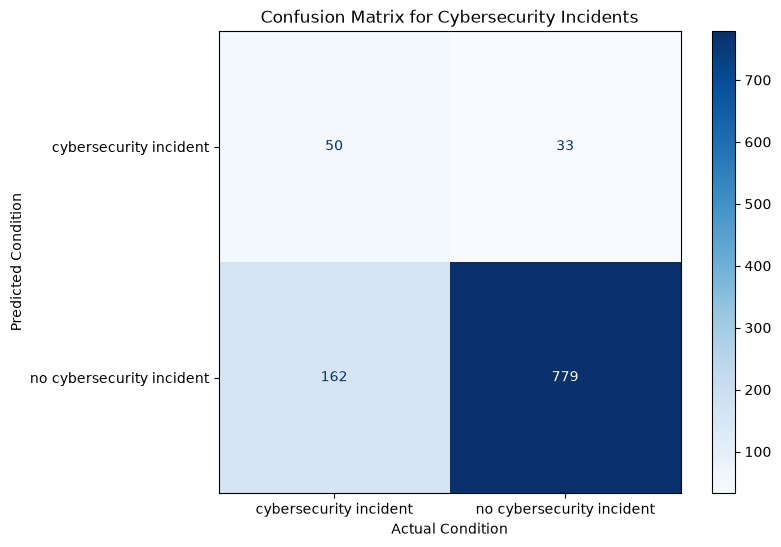

Accuracy: 0.81
Precision: 0.60
Recall: 0.24
F1-score: 0.34


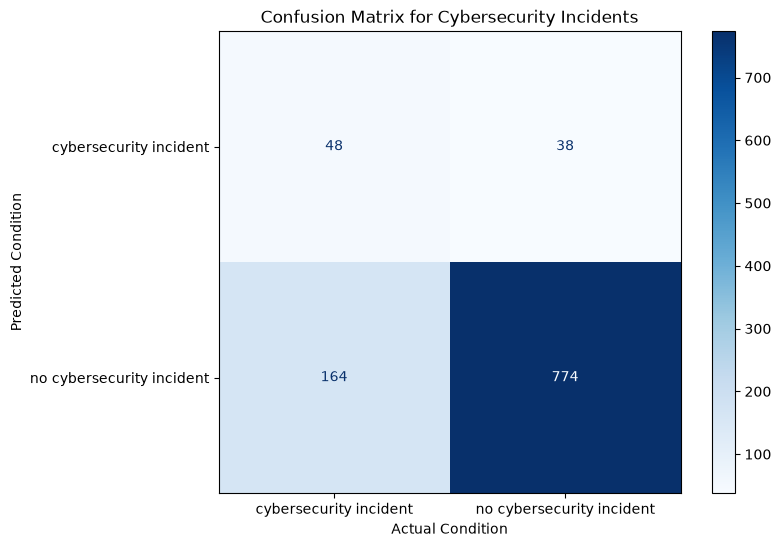

Accuracy: 0.80
Precision: 0.56
Recall: 0.23
F1-score: 0.32


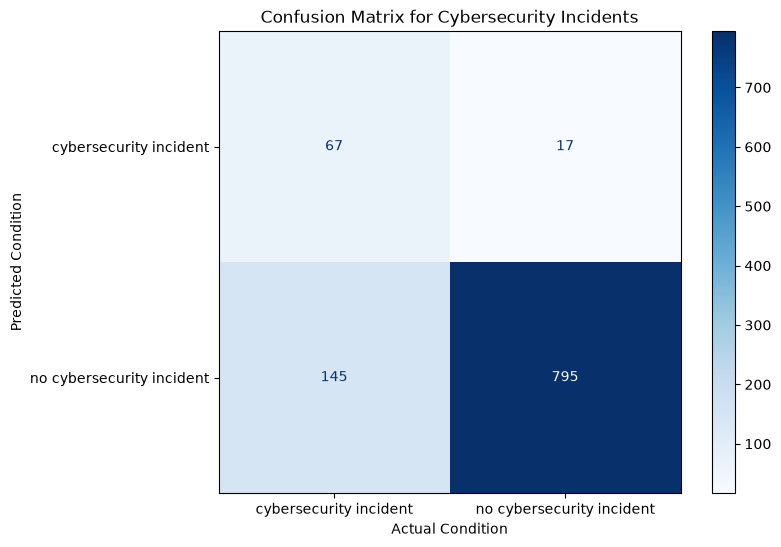

Accuracy: 0.84
Precision: 0.80
Recall: 0.32
F1-score: 0.45


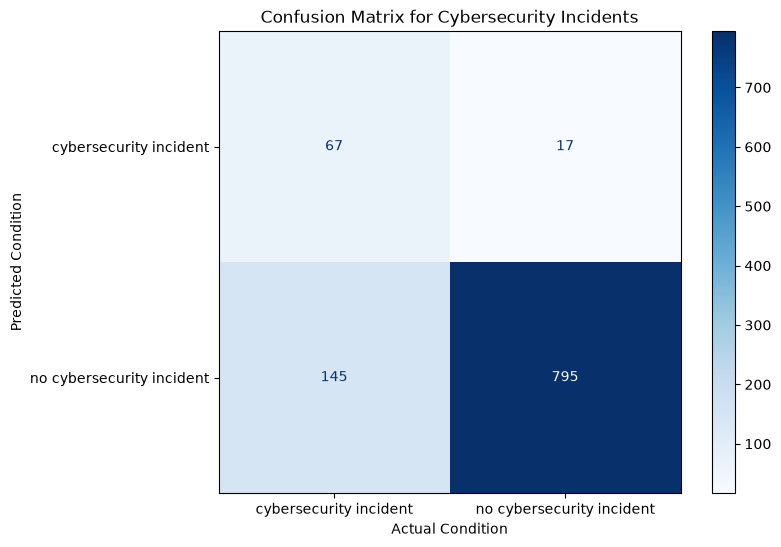

Accuracy: 0.84
Precision: 0.80
Recall: 0.32
F1-score: 0.45


In [44]:
results = []

accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_log_only_numeric)
results.append({'model': 'Logistic Regression without supplier', 'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1})
accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_log_w_dummies)
results.append({'model': 'Logistic Regression with supplier', 'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1})


accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_tree_numeric_features)
results.append({'model': 'Decision Tree without supplier', 'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1})
accuracy, precision, recall, f1 = evaluate_model(complete_data['cybersecurity_incident_past_12m'], predictions_tree_w_dummies)
results.append({'model': 'Decision Tree with supplier', 'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1})

In [45]:

pd.DataFrame(results)

,model,accuracy,precision,recall,f1
0,Logistic Regression without supplier,0.8096,0.6024,0.2358,0.3390
1,Logistic Regression with supplier,0.8027,0.5581,0.2264,0.3221
2,Decision Tree without supplier,0.8418,0.7976,0.3160,0.4527
3,Decision Tree with supplier,0.8418,0.7976,0.3160,0.4527


### Comparison with Splitting Training and Test Data

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    complete_data[features_with_dummies], 
    complete_data['cybersecurity_incident_past_12m'], 
    test_size=0.2, 
    random_state=random_variable
)

In [47]:
tree_depths = range(1, 20)

In [48]:
results_tree = []
for i in tree_depths:
    decision_tree_w_dummies = DecisionTreeClassifier(random_state=random_variable, max_depth=i)
    decision_tree_w_dummies.fit(X_train, y_train)

    # Evaluate on training set
    predictions_tree_w_dummies_train = decision_tree_w_dummies.predict(X_train)
    accuracy_train, precision_train, recall_train, f1_train = evaluate_model(y_train, predictions_tree_w_dummies_train, print_results=False)

    # Evaluate on test set
    predictions_tree_w_dummies_test = decision_tree_w_dummies.predict(X_test)    
    accuracy_test, precision_test, recall_test, f1_test = evaluate_model(y_test, predictions_tree_w_dummies_test, print_results=False)
    
    results_tree.append({'model': f'Max_depth={i}', 
            'accuracy_train': accuracy_train, 'accuracy_test': accuracy_test, 
            'precision_train': precision_train, 'precision_test': precision_test, 
            'recall_train': recall_train, 'recall_test': recall_test, 
             'f1_train': f1_train, 'f1_test  ': f1_test
            })
results_tree_df = pd.DataFrame(results_tree)


/Users/jan/Documents/02_teaching/ohm/01_PPA_ERP/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/jan/Documents/02_teaching/ohm/01_PPA_ERP/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [49]:
results_tree_df

,model,accuracy_train,accuracy_test,precision_train,precision_test,recall_train,recall_test,f1_train,f1_test
0,Max_depth=1,0.7839,0.8293,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,Max_depth=2,0.7973,0.8244,1.0000,0.0000,0.0621,0.0000,0.1170,0.0000
2,Max_depth=3,0.8144,0.7854,0.6543,0.2632,0.2994,0.1429,0.4109,0.1852
3,Max_depth=4,0.8278,0.8000,0.7432,0.3125,0.3107,0.1429,0.4382,0.1961
4,Max_depth=5,0.8364,0.7756,0.7263,0.2609,0.3898,0.1714,0.5074,0.2069
5,Max_depth=6,0.8730,0.7756,0.8411,0.2963,0.5085,0.2286,0.6338,0.2581
6,Max_depth=7,0.8987,0.7366,0.9052,0.1935,0.5932,0.1714,0.7167,0.1818
7,Max_depth=8,0.9280,0.7561,0.9470,0.2857,0.7062,0.2857,0.8091,0.2857
8,Max_depth=9,0.9487,0.7512,0.9355,0.2895,0.8192,0.3143,0.8735,0.3014
9,Max_depth=10,0.9609,0.7366,1.0000,0.2683,0.8192,0.3143,0.9006,0.2895


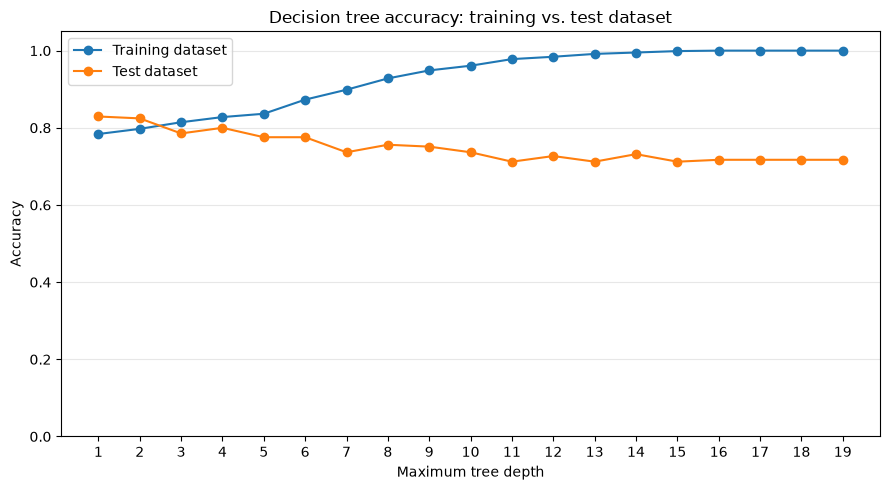

In [50]:


plt.figure(figsize=(9, 5))
plt.plot(tree_depths, results_tree_df['accuracy_train'], marker='o', label='Training dataset')
plt.plot(tree_depths, results_tree_df['accuracy_test'], marker='o', label='Test dataset')
plt.xticks(tree_depths)
plt.ylim(0, 1.05)
plt.xlabel('Maximum tree depth')
plt.ylabel('Accuracy')
plt.title('Decision tree accuracy: training vs. test dataset')
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

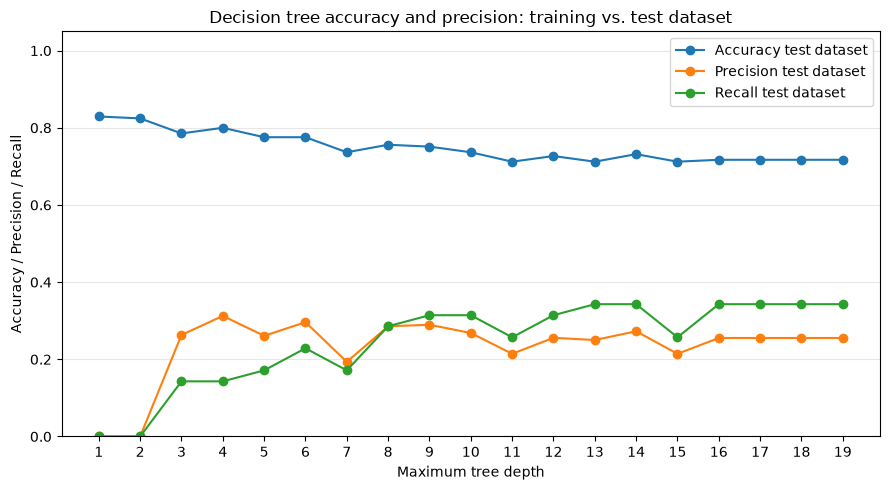

In [51]:


plt.figure(figsize=(9, 5))
plt.plot(tree_depths, results_tree_df['accuracy_test'], marker='o', label='Accuracy test dataset')
plt.plot(tree_depths, results_tree_df['precision_test'], marker='o', label='Precision test dataset')
plt.plot(tree_depths, results_tree_df['recall_test'], marker='o', label='Recall test dataset')
plt.xticks(tree_depths)
plt.ylim(0, 1.05)
plt.xlabel('Maximum tree depth')
plt.ylabel('Accuracy / Precision / Recall')
plt.title('Decision tree accuracy and precision: training vs. test dataset')
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

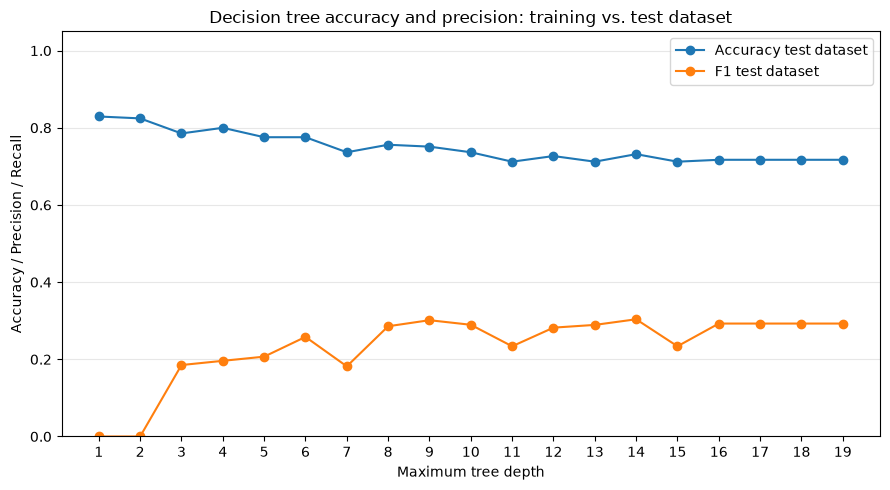

In [52]:

plt.figure(figsize=(9, 5))
plt.plot(tree_depths, results_tree_df['accuracy_test'], marker='o', label='Accuracy test dataset')
plt.plot(tree_depths, results_tree_df['f1_test  '], marker='o', label='F1 test dataset')
plt.xticks(tree_depths)
plt.ylim(0, 1.05)
plt.xlabel('Maximum tree depth')
plt.ylabel('Accuracy / Precision / Recall')
plt.title('Decision tree accuracy and precision: training vs. test dataset')
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

#### Example ROC-Curve

The ROC curve shows the trade-off between the true positive rate (sensitivity/recall) and the false positive rate across all classification thresholds. 

Curves closer to the upper-left corner indicate better discrimination, while the diagonal represents random guessing. 

The AUC summarizes this performance: 1.0 is perfect and 0.5 is no better than chance.

- TPR (True Positive Rate) is Recall
- FPR (False Positive Rate) is the number of cases in which the model is triggering false alerts 

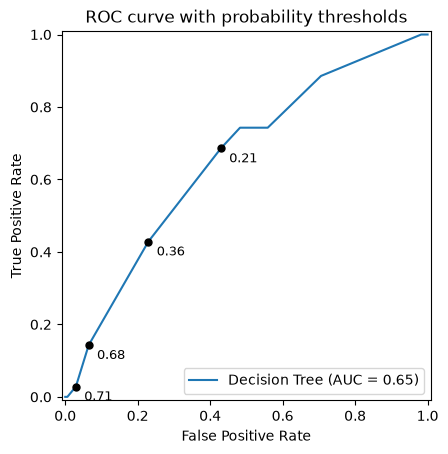

In [53]:

decision_tree_w_dummies = DecisionTreeClassifier(random_state=random_variable, max_depth=4)
decision_tree_w_dummies.fit(X_train, y_train)

# Evaluate on training set
predictions_tree_w_dummies_test = decision_tree_w_dummies.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC for test set predictions
fpr, tpr, thresholds = roc_curve(y_test, predictions_tree_w_dummies_test)
roc_auc = auc(fpr, tpr)
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                          name='Decision Tree')
display.plot()

# Mark representative probability thresholds without overcrowding the curve
thresholds_to_label = [0.2, 0.4, 0.5, 0.6, 0.8]
finite_indices = np.flatnonzero(np.isfinite(thresholds))
indices_to_label = {
    finite_indices[np.argmin(np.abs(thresholds[finite_indices] - target))]
    for target in thresholds_to_label
}

ax = display.ax_
for index in sorted(indices_to_label):
    ax.scatter(fpr[index], tpr[index], color='black', s=25, zorder=3)
    ax.annotate(
        f'{thresholds[index]:.2f}',
        (fpr[index], tpr[index]),
        xytext=(6, -10),
        textcoords='offset points',
        fontsize=9,
    )
ax.set_title('ROC curve with probability thresholds')
plt.show()

**Using 21% as threshold yields a True Positive Rate of about 70% and false Positive Rate about 50%**


In [54]:
predictions_21_percent_thresold = [1 if i >= 0.20 else 0
 for i in decision_tree_w_dummies.predict_proba(X_test)[:, 1]]

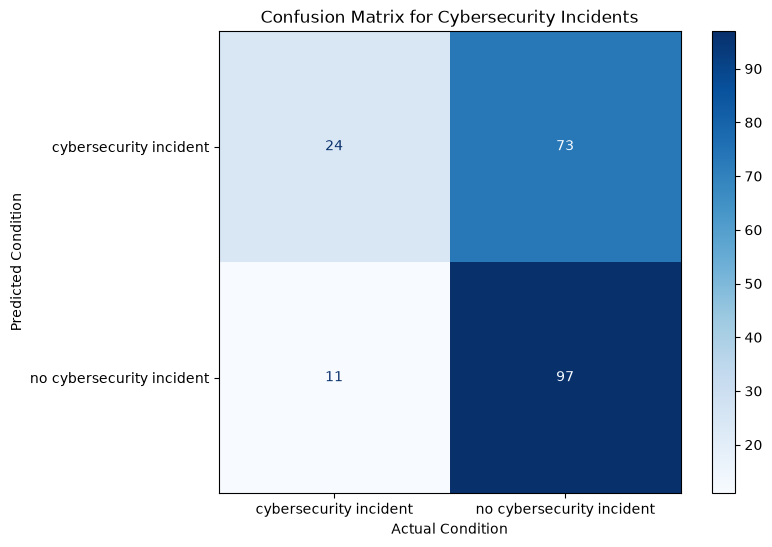

Accuracy: 0.59
Precision: 0.25
Recall: 0.69
F1-score: 0.36


(0.5902, 0.2474, 0.6857, 0.3636)

In [55]:
evaluate_model(y_test, predictions_21_percent_thresold)

True Positive Rate by Hand

In [56]:
24/(11+24)

0.6857142857142857

#### Summary Decision Tree
- Depth of 4 seems to be the best choice for the decision tree if the focus is on accuracy and precision.
- If precision and recall are equivalent important, a higher depth of 9 or even 14 is suitable.
- If Recall is the most important a depth of 14 seems suitable


If we are risk averse from a business perspective. Recall is more important than Precision.

#### Compare logistic regression with TEST und TRAIN dataset

In [57]:
log_reg_simple_w_dummies = LogisticRegression(random_state=random_variable, max_iter=1000)
log_reg_simple_w_dummies.fit(X_train, y_train)
predictions_log_w_dummies_test = log_reg_simple_w_dummies.predict(X_test)

/Users/jan/Documents/02_teaching/ohm/01_PPA_ERP/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


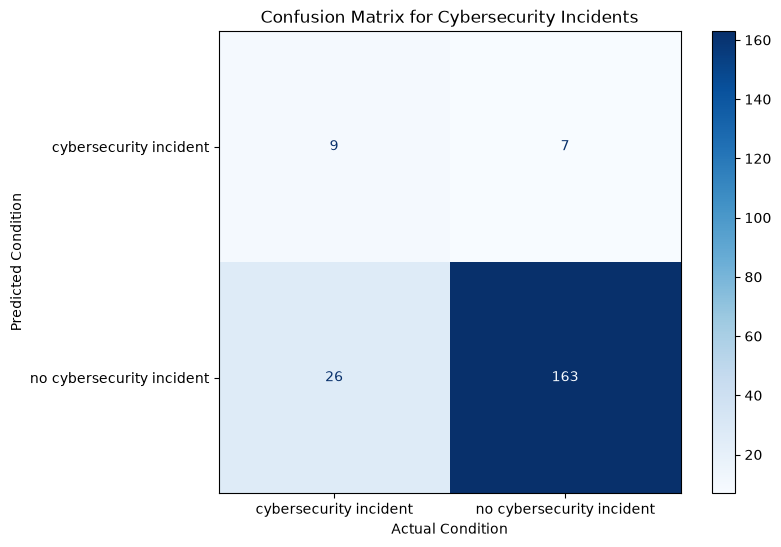

Accuracy: 0.84
Precision: 0.56
Recall: 0.26
F1-score: 0.35


(0.839, 0.5625, 0.2571, 0.3529)

In [58]:
evaluate_model(y_test, predictions_log_w_dummies_test)

#### Summary
If we are risk averse from a business perspective. Recall is more important than Precision. Therefore the logistic regression seems to be the best model in our case.



**Explanation F1-Score**

The F1 score combines precision and recall into one metric:

$$
F_1 = 2 \cdot \frac{\mathrm{Precision} \cdot \mathrm{Recall}}{\mathrm{Precision} + \mathrm{Recall}}
$$

- **Precision:** Of all suppliers predicted to have an incident, how many actually had one?
- **Recall:** Of all suppliers that actually had an incident, how many did the model identify?

The F1 score ranges from 0 to 1. Higher is better. It is especially useful for this cybersecurity dataset because incidents may be relatively uncommon, making accuracy potentially misleading.

A high F1 score requires both good precision and good recall. For example, with precision 0.60 and recall 0.30:

$$
F_1 = 2 \cdot \frac{0.60 \cdot 0.30}{0.60 + 0.30} = 0.40
$$

### Random Forest

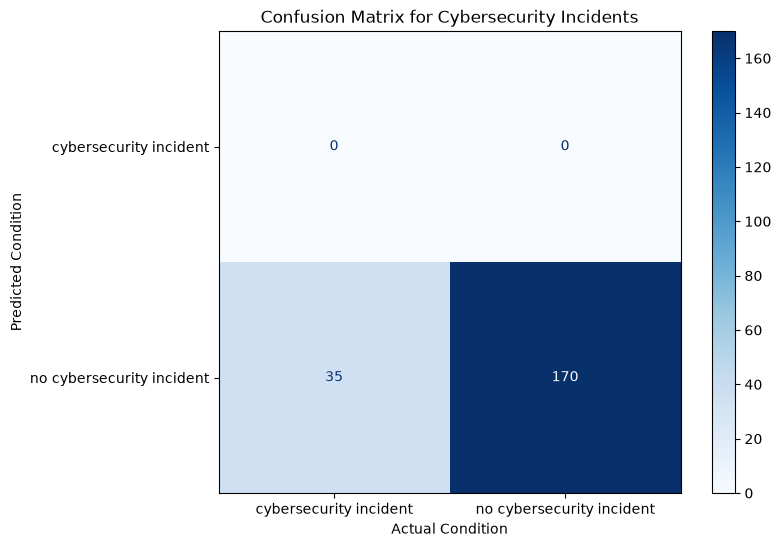

Accuracy: 0.83
Precision: 0.00
Recall: 0.00
F1-score: 0.00


/Users/jan/Documents/02_teaching/ohm/01_PPA_ERP/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


(0.8293, 0.0, 0.0, 0.0)

In [63]:
rf_50 = RandomForestClassifier(n_estimators=50, random_state=random_variable, max_depth=3)
rf_50.fit(X_train, y_train)
predictions_rf_50 = rf_50.predict(X_test)
evaluate_model(y_test, predictions_rf_50)

#### Extract 1. Tree

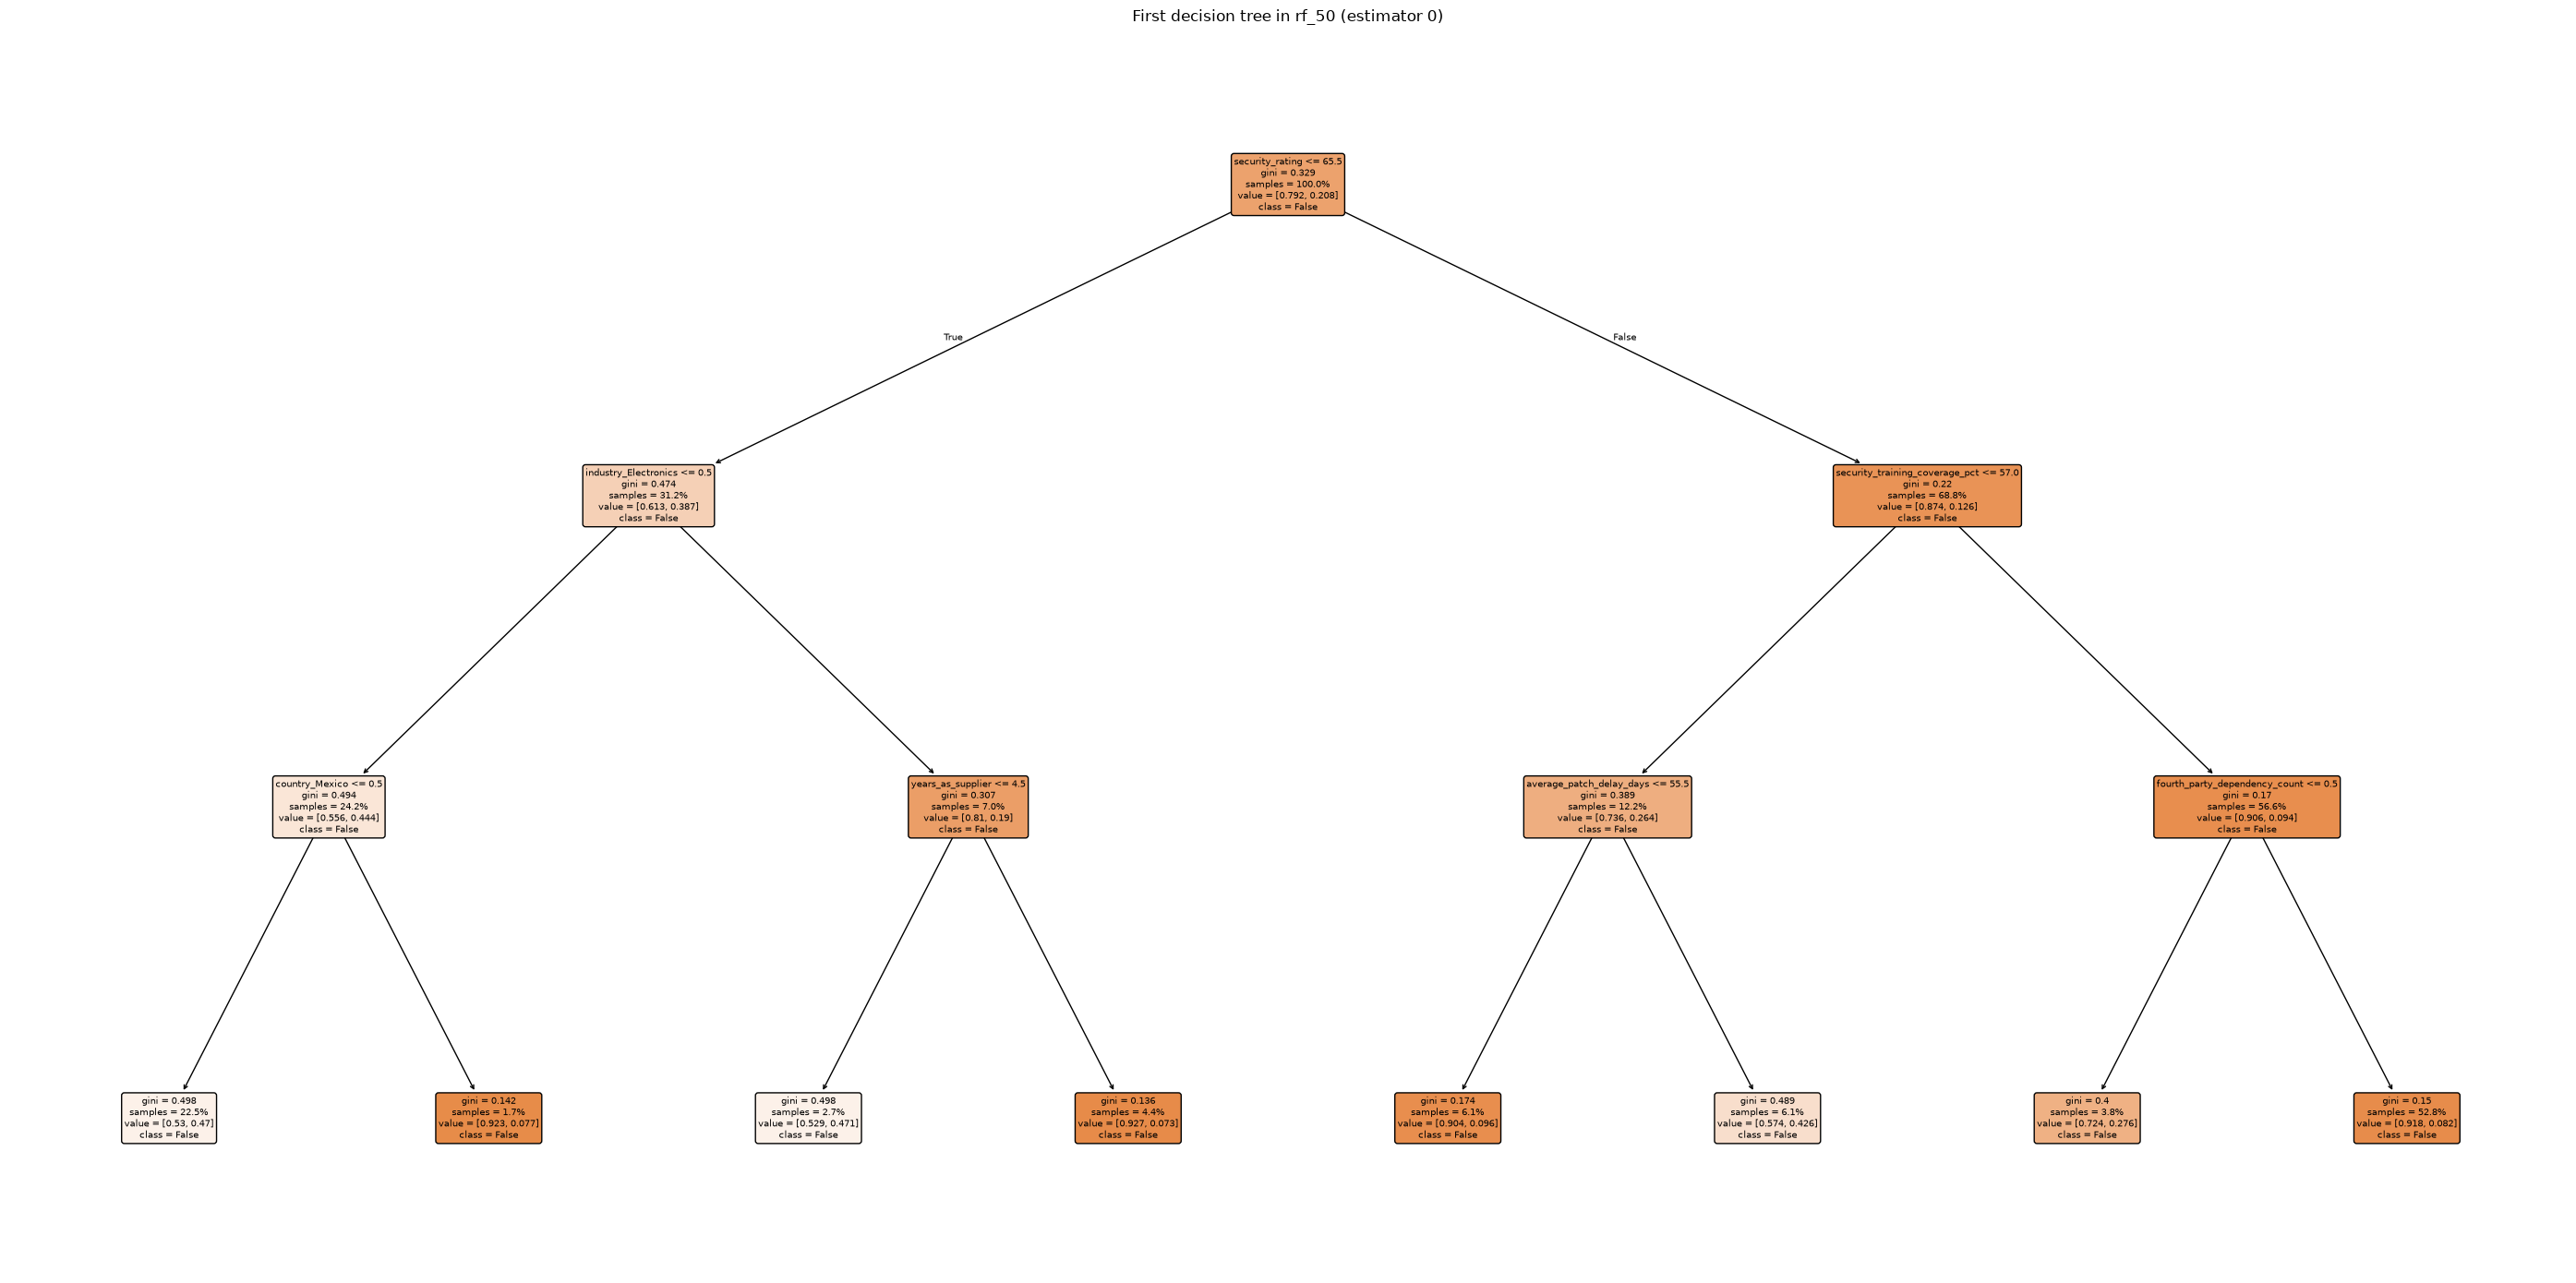

In [ ]:

first_rf_tree = rf_50.estimators_[0]

plt.figure(figsize=(28, 14))
tree.plot_tree(
    first_rf_tree,
    feature_names=X_train.columns,
    class_names=[str(label) for label in rf_50.classes_],
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=7,
)
plt.title("First decision tree in rf_50 (estimator 0)")
plt.tight_layout()
plt.show()

#### Extract 2. Tree

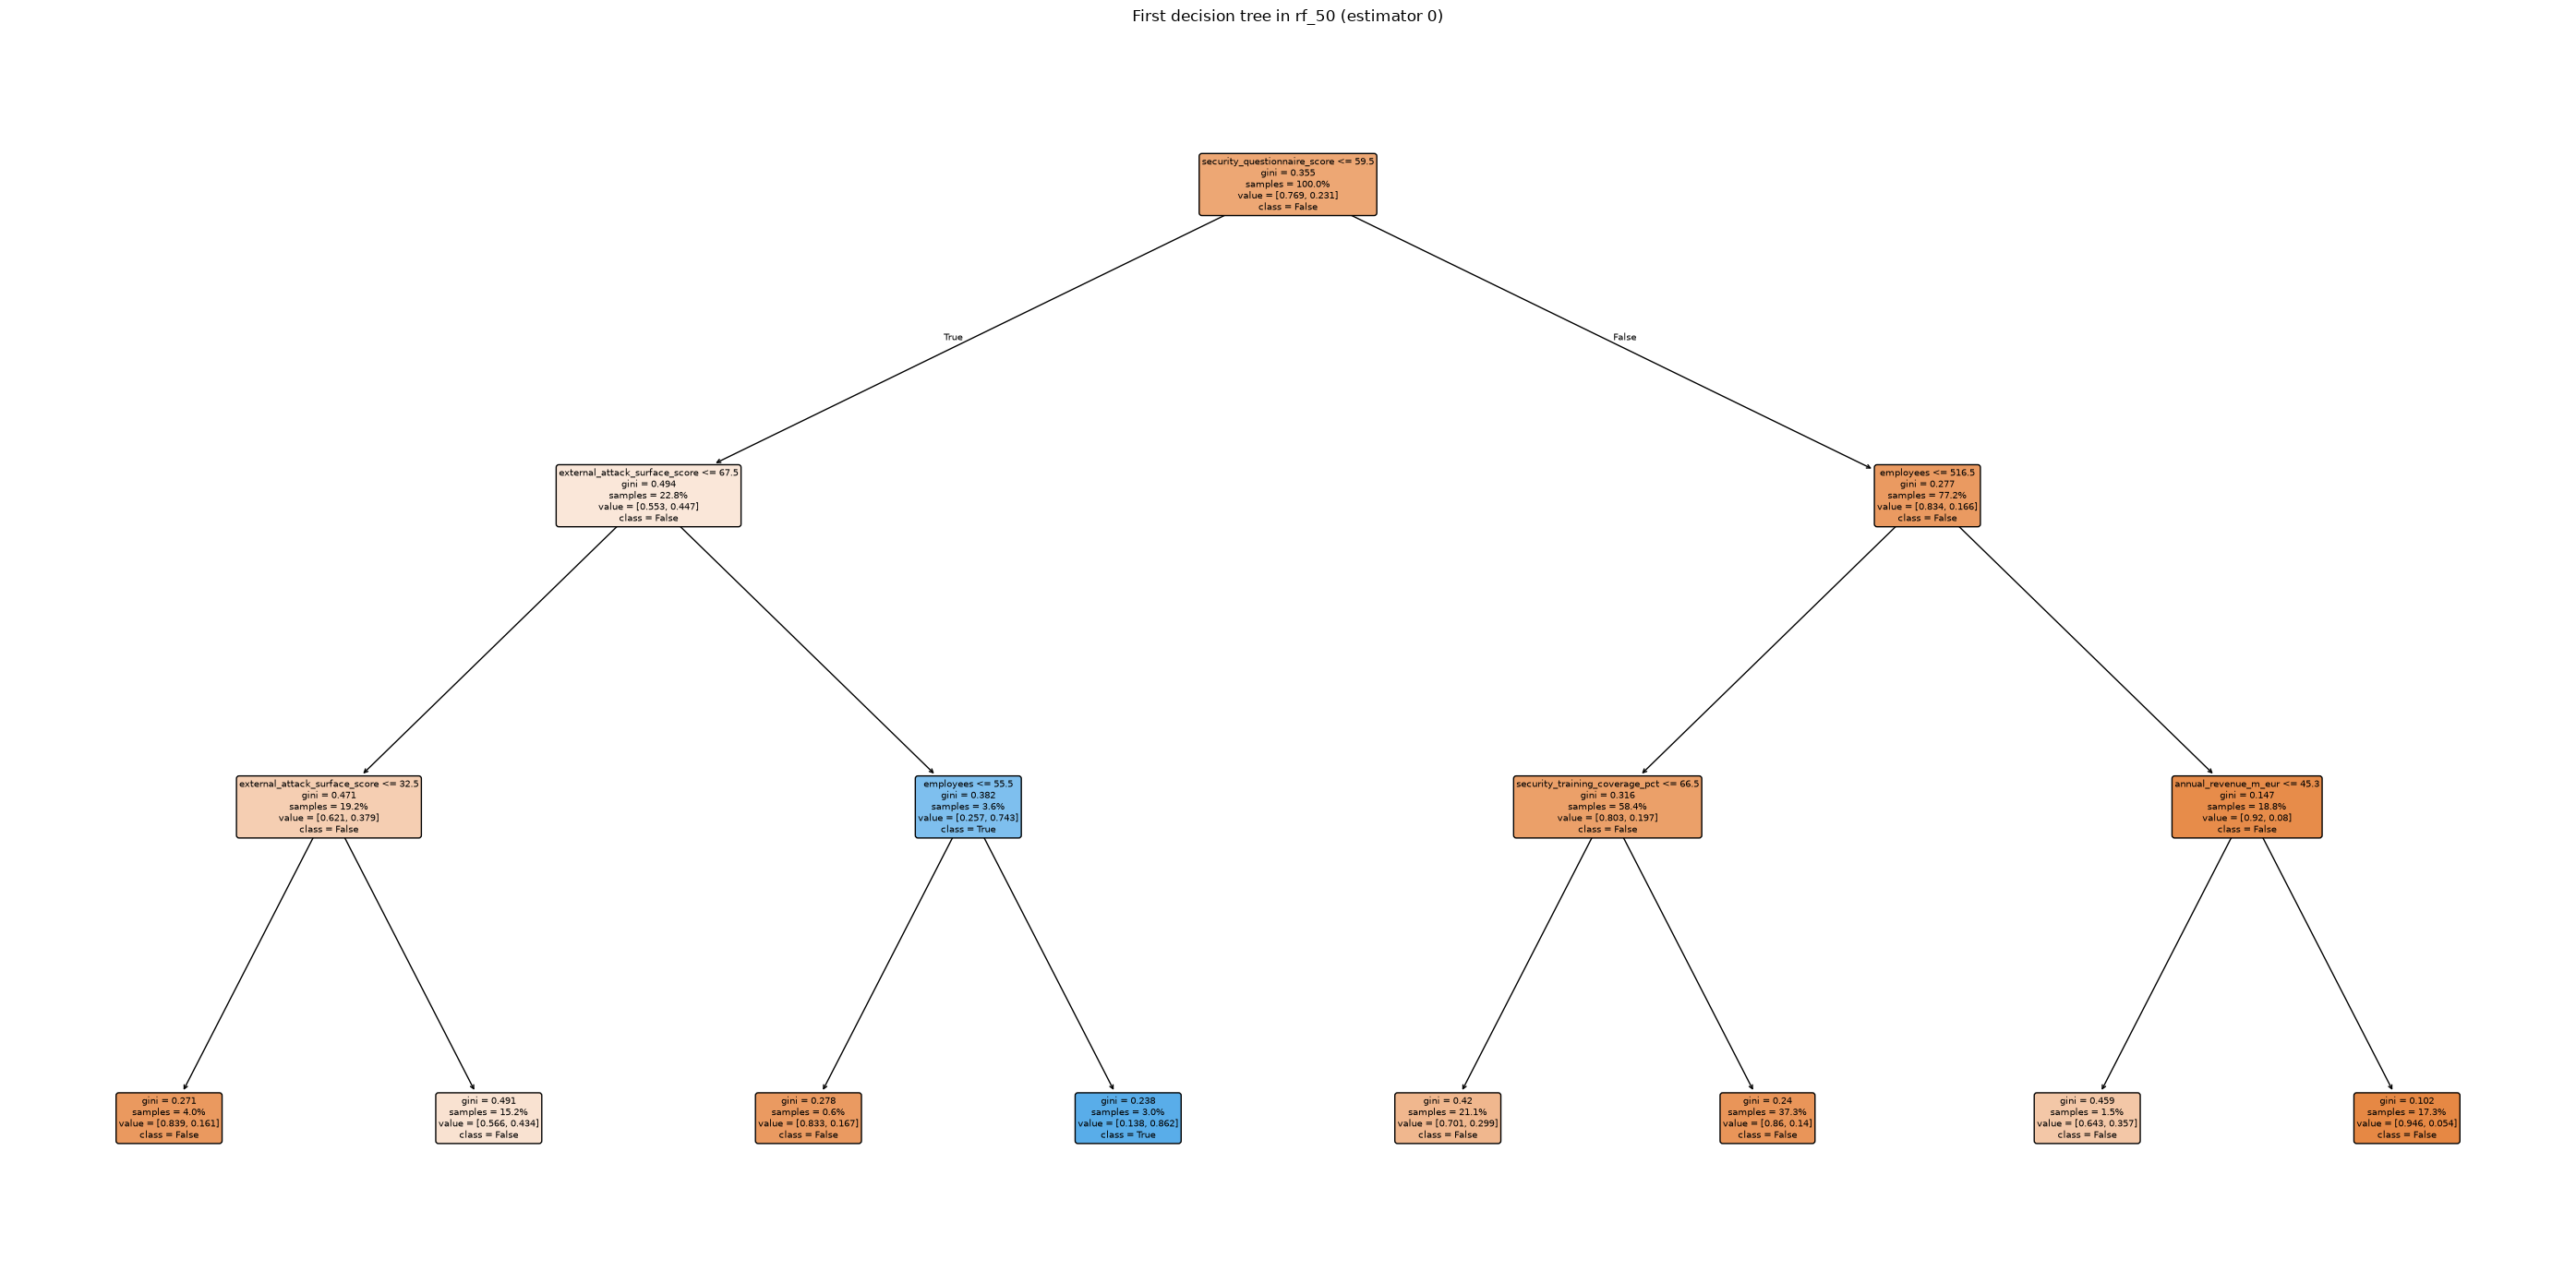

In [ ]:
# Extract and display the first decision tree in the random forest
first_rf_tree = rf_50.estimators_[1]

plt.figure(figsize=(28, 14))
tree.plot_tree(
    first_rf_tree,
    feature_names=X_train.columns,
    class_names=[str(label) for label in rf_50.classes_],
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=7,
)
plt.title("Second decision tree in rf_50 (estimator 1)")
plt.tight_layout()
plt.show()

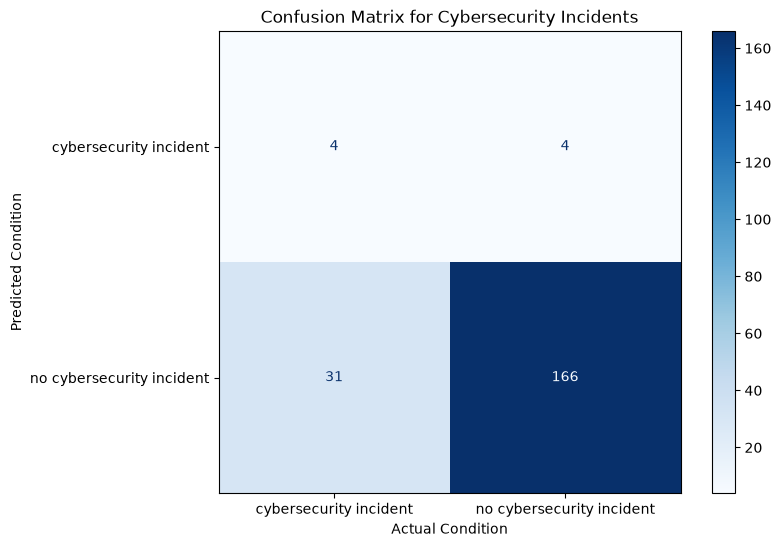

Accuracy: 0.83
Precision: 0.50
Recall: 0.11
F1-score: 0.19


(0.8293, 0.5, 0.1143, 0.186)

In [57]:
rf_100 = RandomForestClassifier(n_estimators=100, random_state=random_variable)
rf_100.fit(X_train, y_train)
predictions_rf_100 = rf_100.predict(X_test)
evaluate_model(y_test, predictions_rf_100)


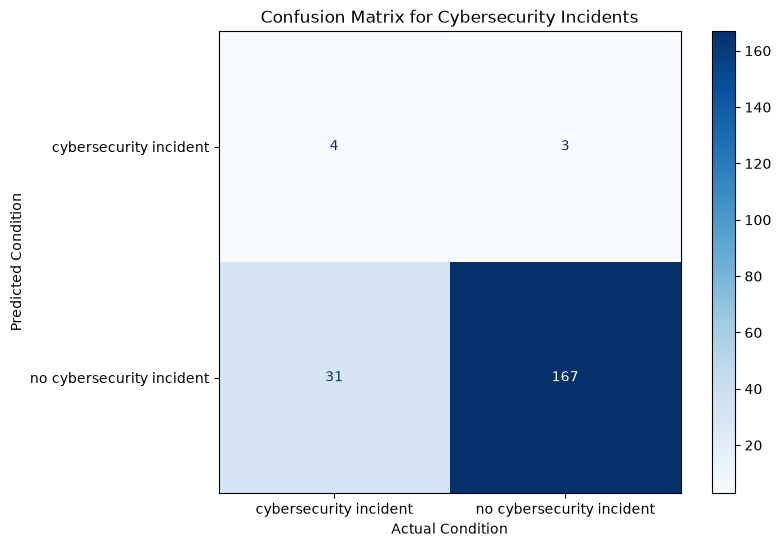

Accuracy: 0.83
Precision: 0.57
Recall: 0.11
F1-score: 0.19


(0.8341, 0.5714, 0.1143, 0.1905)

In [58]:
rf_200 = RandomForestClassifier(n_estimators=200, random_state=random_variable)
rf_200.fit(X_train, y_train)
predictions_rf_200 = rf_200.predict(X_test)
evaluate_model(y_test, predictions_rf_200)

### Boosted Tree

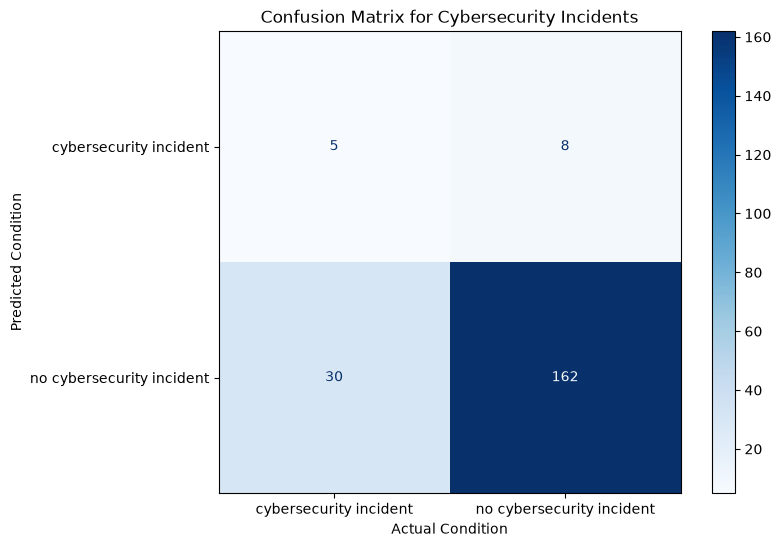

Accuracy: 0.81
Precision: 0.38
Recall: 0.14
F1-score: 0.21


(0.8146, 0.3846, 0.1429, 0.2083)

In [59]:

gb = GradientBoostingClassifier(random_state=random_variable)
gb.fit(X_train, y_train)
predictions_gb = gb.predict(X_test)
evaluate_model(y_test, predictions_gb)

### Gradient Boosting Grid Search

The grid search uses stratified cross-validation so that every fold retains approximately the same class distribution. The models are ranked by F1 score because the incident class is imbalanced.